# Walkthrough: the paper's numbers from the committed results

This notebook reads the CSVs in `results/` and rebuilds the numbers of the
paper's Results section, one section at a time. It needs no downloaded data and
no PyTorch, and runs in a few seconds.

Every number is compared with the value printed in the paper by `check()`. If
a CSV is regenerated and a value moves beyond rounding, the cell fails instead
of showing a different number in silence.

The paper evaluates in three layers, and they do not support the same kind of
statement:

| Layer | Data | Supports claims about |
|---|---|---|
| 1 | Bitcoin OTC, Bitcoin Alpha, Epinions, with published fraud labels | filters on real trust networks |
| 2 | Bitcoin OTC with injected attack profiles | the same, with the caveat of the injection arrangement |
| 3 | Fog-IoT simulation | mechanism only, never operation |

Section numbers below follow the paper. Numbers that need the raw networks,
such as confidence intervals, are listed at the end with the command that
produces them.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RESULTS = Path("results")
real = pd.read_csv(RESULTS / "real.csv")
attack = pd.read_csv(RESULTS / "attack_otc.csv")
grid = pd.read_csv(RESULTS / "full_grid.csv")
ood = pd.read_csv(RESULTS / "out_of_distribution.csv")

NETWORKS = {"real_otc": "Bitcoin OTC", "real_alpha": "Bitcoin Alpha",
            "real_epinions": "Epinions"}


def check(label, value, published, tol=0.0005):
    """Fail if `value` differs from the paper by more than `tol`."""
    status = "ok  " if abs(value - published) <= tol else "FAIL"
    print(f"{status} {label}: {value:.4f}   paper: {published}")
    assert status == "ok  ", label


def layer1(network, filter_, column):
    row = real[(real.scenario == network) & (real["filter"] == filter_)]
    return float(row[column].iloc[0])


for name, d in (("real", real), ("attack_otc", attack), ("full_grid", grid),
                ("out_of_distribution", ood)):
    print(f"{name:20} {len(d):5} rows")

real                    42 rows
attack_otc            1008 rows
full_grid             8400 rows
out_of_distribution    920 rows


## Table 1: the networks

Layer 1 runs one execution per network. The number of raters in each run is
the second column of Table 1. The full counts are checked against Kumar et al.
(2018) when `python -m realdata.download` ingests the data.

In [2]:
for network, raters in (("real_otc", 4814), ("real_alpha", 3286),
                        ("real_epinions", 120486)):
    check(f"{NETWORKS[network]} raters", layer1(network, "dpc", "n_nodes"),
          raters, tol=0)

ok   Bitcoin OTC raters: 4814.0000   paper: 4814
ok   Bitcoin Alpha raters: 3286.0000   paper: 3286
ok   Epinions raters: 120486.0000   paper: 120486


## 4.1 Detection on the real networks (Table 3)

The area under the ROC curve of each filter, detecting recommendations issued
by users labelled fraudulent. The CSV holds the point estimates; the 95%
intervals resample raters and need the raw networks (see the end).

In [3]:
TABLE3 = {
    "rev2":       (0.824, 0.576, 0.560),
    "reputation": (0.794, 0.611, 0.652),
    "tree3":      (0.738, 0.610, 0.667),
    "mlp":        (0.688, 0.578, 0.699),
    "dpc_han":    (0.662, 0.531, 0.549),
    "deeptrust":  (0.642, 0.661, 0.607),
    "consensus":  (0.624, 0.542, 0.551),
    "dpc":        (0.578, 0.498, 0.537),
}
auc = real.pivot_table(index="filter", columns="scenario", values="auc")
auc = auc.loc[list(TABLE3), list(NETWORKS)].rename(columns=NETWORKS)
for filter_, published in TABLE3.items():
    for network, value in zip(NETWORKS.values(), published):
        check(f"AUC {filter_:10} {network:13}", auc.loc[filter_, network], value)
auc.round(3)

ok   AUC rev2       Bitcoin OTC  : 0.8237   paper: 0.824
ok   AUC rev2       Bitcoin Alpha: 0.5763   paper: 0.576
ok   AUC rev2       Epinions     : 0.5604   paper: 0.56
ok   AUC reputation Bitcoin OTC  : 0.7941   paper: 0.794
ok   AUC reputation Bitcoin Alpha: 0.6107   paper: 0.611
ok   AUC reputation Epinions     : 0.6523   paper: 0.652
ok   AUC tree3      Bitcoin OTC  : 0.7377   paper: 0.738
ok   AUC tree3      Bitcoin Alpha: 0.6101   paper: 0.61
ok   AUC tree3      Epinions     : 0.6666   paper: 0.667
ok   AUC mlp        Bitcoin OTC  : 0.6875   paper: 0.688
ok   AUC mlp        Bitcoin Alpha: 0.5777   paper: 0.578
ok   AUC mlp        Epinions     : 0.6995   paper: 0.699
ok   AUC dpc_han    Bitcoin OTC  : 0.6623   paper: 0.662
ok   AUC dpc_han    Bitcoin Alpha: 0.5307   paper: 0.531
ok   AUC dpc_han    Epinions     : 0.5489   paper: 0.549
ok   AUC deeptrust  Bitcoin OTC  : 0.6424   paper: 0.642
ok   AUC deeptrust  Bitcoin Alpha: 0.6613   paper: 0.661
ok   AUC deeptrust  Epinions     

scenario,Bitcoin OTC,Bitcoin Alpha,Epinions
filter,,,
rev2,0.824,0.576,0.560
reputation,0.794,0.611,0.652
tree3,0.738,0.610,0.667
mlp,0.688,0.578,0.699
dpc_han,0.662,0.531,0.549
deeptrust,0.642,0.661,0.607
consensus,0.624,0.542,0.551
dpc,0.578,0.498,0.537


In [4]:
VARIANTS = ["dpc_entropy", "dpc_cardinality", "dpc_recommender",
            "dpc_outlier", "dpc_bimodal"]
gap = max(abs(layer1(n, v, "auc") - layer1(n, "dpc", "auc"))
          for n in NETWORKS for v in VARIANTS)
check("largest AUC distance between a DPC variant and the main one", gap, 0.053,
      tol=0.0006)

ok   largest AUC distance between a DPC variant and the main one: 0.0528   paper: 0.053


## 4.2 The first hypothesis

The hypothesis asks for an F1-score within five percentage points of the
neural network against three attacks. Only layers 2 and 3 know the attack type.

In layer 2 every rating of an injected profile is labelled malicious. The gap
is DPC minus neural network, in points, averaged over the four proportions and
three seeds.

In [5]:
f1 = attack[attack["filter"].isin(["dpc", "mlp"])].pivot_table(
    index="filter", columns="attack", values="f1")
for attack_type, published in (("collusion", -42.8), ("bad_mouthing", -43.7),
                               ("ballot_stuffing", -45.5)):
    gap = 100 * (f1.loc["dpc", attack_type] - f1.loc["mlp", attack_type])
    check(f"layer 2 F1 gap, {attack_type}", gap, published, tol=0.05)

ok   layer 2 F1 gap, collusion: -42.7743   paper: -42.8
ok   layer 2 F1 gap, bad_mouthing: -43.7341   paper: -43.7
ok   layer 2 F1 gap, ballot_stuffing: -45.5290   paper: -45.5


With the per-recommendation label, only the distorted rating about the
attacked target counts as malicious. DPC falls below chance.

In [6]:
three = attack[attack.attack.isin(["bad_mouthing", "ballot_stuffing", "collusion"])]
per_attack = three.groupby(["filter", "attack"]).auc_recommendation.mean()
for filter_, low, high in (("dpc", 0.411, 0.459), ("mlp", 0.910, 0.934)):
    check(f"per-recommendation AUC, {filter_}, lowest", per_attack[filter_].min(), low,
          tol=0.0006)
    check(f"per-recommendation AUC, {filter_}, highest", per_attack[filter_].max(), high,
          tol=0.0006)

ok   per-recommendation AUC, dpc, lowest: 0.4112   paper: 0.411
ok   per-recommendation AUC, dpc, highest: 0.4593   paper: 0.459
ok   per-recommendation AUC, mlp, lowest: 0.9098   paper: 0.91
ok   per-recommendation AUC, mlp, highest: 0.9340   paper: 0.934


Layer 1 has no attack type, so it does not test the hypothesis. The F1
values are still reported. DPC discards a third to a half of the ratings, which
raises F1 through recall: on Epinions its F1 is that of a random draw with the
same discard rate.

In [7]:
for network, dpc, mlp in (("real_otc", 0.378, 0.397), ("real_alpha", 0.352, 0.207),
                          ("real_epinions", 0.012, 0.043)):
    check(f"F1 DPC, {NETWORKS[network]}", layer1(network, "dpc", "f1"), dpc)
    check(f"F1 neural network, {NETWORKS[network]}", layer1(network, "mlp", "f1"), mlp)

rates = {n: layer1(n, "dpc", "discard_rate") for n in NETWORKS}
print({NETWORKS[n]: round(r, 3) for n, r in rates.items()})
check("Epinions DPC discard rate", rates["real_epinions"], 0.517, tol=0.0006)

pi = layer1("real_epinions", "dpc", "malicious_rate")
q = rates["real_epinions"]
check("F1 of a random draw with DPC's discard rate, Epinions",
      2 * pi * q / (pi + q), 0.012)

ok   F1 DPC, Bitcoin OTC: 0.3782   paper: 0.378
ok   F1 neural network, Bitcoin OTC: 0.3969   paper: 0.397
ok   F1 DPC, Bitcoin Alpha: 0.3519   paper: 0.352
ok   F1 neural network, Bitcoin Alpha: 0.2071   paper: 0.207
ok   F1 DPC, Epinions: 0.0116   paper: 0.012
ok   F1 neural network, Epinions: 0.0435   paper: 0.043
{'Bitcoin OTC': 0.351, 'Bitcoin Alpha': 0.331, 'Epinions': 0.517}
ok   Epinions DPC discard rate: 0.5175   paper: 0.517
ok   F1 of a random draw with DPC's discard rate, Epinions: 0.0121   paper: 0.012


Outside the training distribution the trained models lose their
advantage. In the calibrated simulation, training on one attack and measuring
on another: (layer 3, mechanism only)

In [8]:
cal = ood[ood.scenario == "calibrated"]
for filter_, inside, outside in (("mlp", 0.997, 0.429), ("deeptrust", 0.996, 0.744)):
    s = cal[cal["filter"] == filter_]
    check(f"{filter_} AUC, same attack", s[s.in_distribution == 1].auc.mean(), inside,
          tol=0.0006)
    check(f"{filter_} AUC, other attack", s[s.in_distribution == 0].auc.mean(), outside,
          tol=0.0006)
check("neural network, lowest cell outside the distribution",
      cal[(cal["filter"] == "mlp") & (cal.in_distribution == 0)].auc.min(), 0.003,
      tol=0.0006)

ok   mlp AUC, same attack: 0.9972   paper: 0.997
ok   mlp AUC, other attack: 0.4289   paper: 0.429
ok   deeptrust AUC, same attack: 0.9958   paper: 0.996
ok   deeptrust AUC, other attack: 0.7442   paper: 0.744
ok   neural network, lowest cell outside the distribution: 0.0032   paper: 0.003


## 4.3 Cost

Inference memory on Bitcoin OTC is the `tracemalloc` peak, which sees NumPy
allocations. It does not see PyTorch, so the Deep Trust value in this column
is not valid; the paper uses process memory for it, measured by
`python -m analysis.memory_instruments`.

Training time is wall-clock time and moves with machine load; the paper uses
it as an order of magnitude. DPC has no training.

In [9]:
for filter_, published in (("dpc", 22.2), ("mlp", 1.3)):
    check(f"peak inference memory, {filter_}, Bitcoin OTC (MB)",
          layer1("real_otc", filter_, "peak_memory_kb") / 1024, published, tol=0.05)
check("training time, neural network, Epinions (s)",
      layer1("real_epinions", "mlp", "train_time_s"), 51.5, tol=8)
check("training time, Deep Trust, Epinions (s)",
      layer1("real_epinions", "deeptrust", "train_time_s"), 307, tol=40)
check("training time, DPC (s)", layer1("real_epinions", "dpc", "train_time_s"), 0, tol=0)

ok   peak inference memory, dpc, Bitcoin OTC (MB): 22.2465   paper: 22.2
ok   peak inference memory, mlp, Bitcoin OTC (MB): 1.3150   paper: 1.3
ok   training time, neural network, Epinions (s): 51.5190   paper: 51.5
ok   training time, Deep Trust, Epinions (s): 306.8875   paper: 307
ok   training time, DPC (s): 0.0000   paper: 0


## 4.4 Why density pre-filtering fails (Table 4)

AUC against the proportion of malicious nodes in the calibrated simulation,
mean of 50 runs per cell (layer 3, mechanism only). The filters that judge by
the deviation from the consensus lose the most as attackers grow; the
fixed-anchor adaptation of Han et al. loses about four times less; the trained
models barely move.

In [10]:
TABLE4 = {
    "dpc":        (0.897, 0.864, 0.789, 0.673, -0.224),
    "consensus":  (0.971, 0.919, 0.834, 0.756, -0.214),
    "rev2":       (0.873, 0.821, 0.763, 0.704, -0.168),
    "reputation": (0.975, 0.964, 0.922, 0.833, -0.142),
    "dpc_han":    (0.782, 0.769, 0.752, 0.729, -0.053),
    "tree3":      (0.990, 0.985, 0.980, 0.966, -0.024),
    "deeptrust":  (0.999, 0.996, 0.992, 0.980, -0.019),
    "mlp":        (0.999, 0.997, 0.992, 0.981, -0.018),
}
calibrated = grid[grid.scenario == "calibrated"]
runs = calibrated.groupby(["filter", "mu"]).size()
check("runs per cell", runs.min(), 50, tol=0)
check("runs per cell (max)", runs.max(), 50, tol=0)

table4 = calibrated.pivot_table(index="filter", columns="mu", values="auc").loc[list(TABLE4)]
table4["change"] = table4[0.4] - table4[0.1]
for filter_, published in TABLE4.items():
    for column, value in zip(table4.columns, published):
        check(f"{filter_:10} {column}", table4.loc[filter_, column], value)
table4.round(3)

ok   runs per cell: 50.0000   paper: 50
ok   runs per cell (max): 50.0000   paper: 50
ok   dpc        0.1: 0.8969   paper: 0.897
ok   dpc        0.2: 0.8644   paper: 0.864
ok   dpc        0.3: 0.7894   paper: 0.789
ok   dpc        0.4: 0.6734   paper: 0.673
ok   dpc        change: -0.2235   paper: -0.224
ok   consensus  0.1: 0.9706   paper: 0.971
ok   consensus  0.2: 0.9188   paper: 0.919
ok   consensus  0.3: 0.8337   paper: 0.834
ok   consensus  0.4: 0.7563   paper: 0.756
ok   consensus  change: -0.2142   paper: -0.214
ok   rev2       0.1: 0.8726   paper: 0.873
ok   rev2       0.2: 0.8211   paper: 0.821
ok   rev2       0.3: 0.7629   paper: 0.763
ok   rev2       0.4: 0.7044   paper: 0.704
ok   rev2       change: -0.1683   paper: -0.168
ok   reputation 0.1: 0.9746   paper: 0.975
ok   reputation 0.2: 0.9640   paper: 0.964
ok   reputation 0.3: 0.9216   paper: 0.922
ok   reputation 0.4: 0.8326   paper: 0.833
ok   reputation change: -0.1420   paper: -0.142
ok   dpc_han    0.1: 0.7824   pape

mu,0.1,0.2,0.3,0.4,change
filter,,,,,
dpc,0.897,0.864,0.789,0.673,-0.224
consensus,0.971,0.919,0.834,0.756,-0.214
rev2,0.873,0.821,0.763,0.704,-0.168
reputation,0.975,0.964,0.922,0.833,-0.142
dpc_han,0.782,0.769,0.752,0.729,-0.053
tree3,0.990,0.985,0.980,0.966,-0.024
deeptrust,0.999,0.996,0.992,0.980,-0.019
mlp,0.999,0.997,0.992,0.981,-0.018


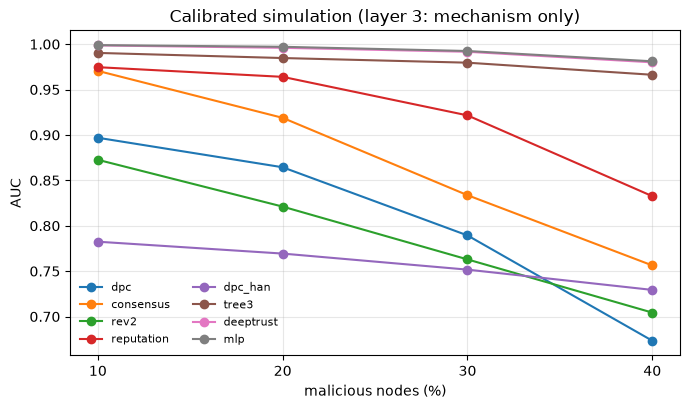

In [11]:
fig, ax = plt.subplots(figsize=(7, 4.2))
for filter_ in TABLE4:
    ax.plot([10, 20, 30, 40], table4.loc[filter_, [0.1, 0.2, 0.3, 0.4]], marker="o",
            label=filter_)
ax.set_xlabel("malicious nodes (%)")
ax.set_ylabel("AUC")
ax.set_xticks([10, 20, 30, 40])
ax.set_title("Calibrated simulation (layer 3: mechanism only)")
ax.legend(ncol=2, fontsize=8, frameon=False)
ax.grid(alpha=0.3)
plt.tight_layout()

## 4.5 The second hypothesis

On the real networks the error of the Trust Score is measured against the mean
rating of users labelled benign. DPC pre-filtering raises the error on Bitcoin
OTC and Epinions. The paper's statement that the increase is above zero, and
that on Bitcoin Alpha it is within noise, rests on intervals that resample
targets and need the raw networks.

In [12]:
for network, without, with_ in (("real_otc", 0.063, 0.073),
                               ("real_epinions", 0.072, 0.088)):
    check(f"Trust Score error without filter, {NETWORKS[network]}",
          layer1(network, "dpc", "mae_unfiltered"), without)
    check(f"Trust Score error with DPC, {NETWORKS[network]}",
          layer1(network, "dpc", "mae_filtered"), with_)
real[real["filter"] == "dpc"].set_index("scenario")[
    ["mae_unfiltered", "mae_filtered", "mae_reduction"]].rename(index=NETWORKS).round(4)

ok   Trust Score error without filter, Bitcoin OTC: 0.0630   paper: 0.063
ok   Trust Score error with DPC, Bitcoin OTC: 0.0726   paper: 0.073
ok   Trust Score error without filter, Epinions: 0.0721   paper: 0.072
ok   Trust Score error with DPC, Epinions: 0.0878   paper: 0.088


,mae_unfiltered,mae_filtered,mae_reduction
scenario,,,
Bitcoin Alpha,0.0485,0.0498,-0.0012
Epinions,0.0721,0.0878,-0.0157
Bitcoin OTC,0.0630,0.0726,-0.0096


In the calibrated simulation the opposite happens: every DPC variant
lowers the error, even though none reaches an average precision of 0.40.
There, discarding cleans what remains even with poor detection (layer 3,
mechanism only).

In [13]:
mean = calibrated.groupby("filter")[["mae_reduction", "average_precision"]].mean()
dpc_family = mean[mean.index.str.startswith("dpc") & ~mean.index.str.startswith("dpc_han")]
print(dpc_family.round(4))
check("DPC variants that lower the error", float((dpc_family.mae_reduction > 0).sum()), 6,
      tol=0)
check("highest average precision among them",
      dpc_family[dpc_family.mae_reduction > 0].average_precision.max(), 0.396, tol=0.004)

                 mae_reduction  average_precision
filter                                           
dpc                     0.0172             0.3888
dpc_bimodal             0.0195             0.3783
dpc_cardinality         0.0178             0.3888
dpc_entropy             0.0145             0.3939
dpc_outlier             0.0131             0.3888
dpc_recommender         0.0195             0.3963
ok   DPC variants that lower the error: 6.0000   paper: 6
ok   highest average precision among them: 0.3963   paper: 0.396


## What needs the raw networks

The numbers below depend on per-recommendation predictions or on the full
networks, which are not committed. Download the data first with
`python -m realdata.download`.

| Paper | Command |
|---|---|
| 95% intervals of Table 3, by rater | `python paper_tables.py --redo` |
| F1 non-inferiority intervals; new versus seen raters; Trust Score error intervals by target; independent reference for H2; Deep Trust epochs | `python -m analysis.layer1_predictions`, then `python -m analysis.paired_comparisons` |
| Process memory, cost with 1 and 4 threads | `python -m analysis.memory_instruments`, `python -m analysis.cost_by_threads` |
| Batch-size cost and the Raspberry Pi 3 budget | `python scalability.py` |
| Consensus capture | `python -m analysis.consensus_capture otc` |
| Feature-weighting ceiling | `python -m analysis.feature_weighting otc` |
| Anchors versus clustering in the Han et al. adaptation | `python -m analysis.han_ablation --sweep` |
| DPC and REV2 against their papers; shuffled-label and oracle controls | `python -m validation.graded`, `python -m validation.rev2_kumar2018`, `python -m validation.controls` |

To regenerate the CSVs themselves: `python -m realdata.real_experiment otc
alpha epinions` (layer 1), `python -m realdata.attack_experiment otc`
(layer 2), `python run_grid.py` (layer 3) and `python out_of_distribution.py`.
After that, run this notebook again: any value that moved fails its check.